# CSE 4095 Class 2: Classification with Scikit-Learn and AI
Use AI as a coding agent, but inspect and explain every major decision.

**Workflow:** define the problem → choose features → split the data → preprocess → establish a baseline → train → predict → evaluate → inspect errors → experiment

## Setup: load the dataset
Upload `class1_student_habits.csv` to the Colab file sidebar, then run the notebook from top to bottom.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Only blank cells count as missing, so "None" stays a real
# prior_programming_experience answer instead of turning into NaN.
df = pd.read_csv("class1_student_habits.csv", keep_default_na=False, na_values=[""])

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.head()

Rows: 250, Columns: 10


,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


In [2]:
# Missing values by column (blank cells only)
df.isna().sum()

student_id                       0
study_hours_per_week             9
sleep_hours_per_night           12
attendance_rate                  0
practice_problems_per_week       0
prior_programming_experience     7
study_group                      0
commute_minutes                  0
quiz_average                     0
exam_score                       0
dtype: int64

## Part 1: Define a Classification Problem
Create `high_exam_score`: **Yes** if `exam_score >= 80`, otherwise **No**.

In [3]:
TARGET = "high_exam_score"
df[TARGET] = (df["exam_score"] >= 80).map({True: "Yes", False: "No"})

class_distribution = pd.DataFrame({
    "count": df[TARGET].value_counts(),
    "percent": (df[TARGET].value_counts(normalize=True) * 100).round(1),
})
class_distribution

,count,percent
high_exam_score,,
No,151,60.4
Yes,99,39.6


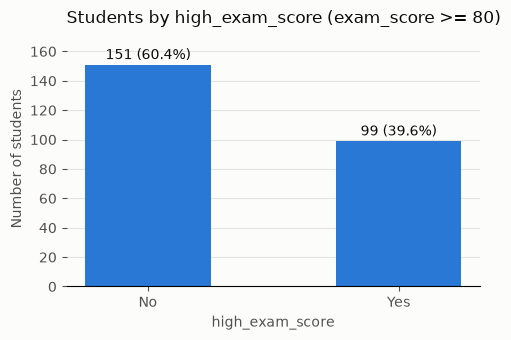

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
fig.patch.set_facecolor("#fcfcfb")
ax.set_facecolor("#fcfcfb")

bars = ax.bar(class_distribution.index, class_distribution["count"], width=0.5, color="#2a78d6")
for bar, count, percent in zip(bars, class_distribution["count"], class_distribution["percent"]):
    ax.annotate(f"{count} ({percent}%)", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points", ha="center", color="#0b0b0b")

ax.set_title("Students by high_exam_score (exam_score >= 80)", color="#0b0b0b", loc="left")
ax.set_xlabel("high_exam_score", color="#52514e")
ax.set_ylabel("Number of students", color="#52514e")
ax.set_ylim(0, class_distribution["count"].max() * 1.15)
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

### ✍️ Questions

**1. Why is predicting exam_score a regression problem?**

_Your answer:_ TODO

**2. Why is predicting high_exam_score a classification problem?**

_Your answer:_ TODO

**3. How many students belong to each class?**

_Your answer:_ TODO

**4. What percentage of students belong to each class?**

_Your answer:_ TODO

## Part 2: Choose the Features
Primary model features: study hours, sleep, attendance, practice problems, prior programming experience, study group, and commute time.
Not used: `student_id`, `exam_score`, `quiz_average`.

In [5]:
RANDOM_STATE = 42

NUMERIC_FEATURES = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
]
CATEGORICAL_FEATURES = [
    "prior_programming_experience",
    "study_group",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURES]
y = df[TARGET]
print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (250, 7), y shape: (250,)


### 📝 Notes from the AI session
_Reference only. Answer the questions in your own words._

| Column | Used? | Why |
|---|---|---|
| study hours, sleep, attendance, practice, prior experience, study group | ✅ | Habits and background known before the exam |
| `commute_minutes` | ✅ | Legitimate and known in advance, but its correlation with exam score is weak (r = 0.07) |
| `student_id` | ❌ | An identifier, not a property of the student |
| `exam_score` | ❌ | The target was built from it (Part 12 tests what happens if it is used) |
| `quiz_average` | ❌ for now | Held out until Part 13 |

### ✍️ Questions

**Why should student_id normally not be used as a predictor?**

_Your answer:_ TODO

**Why would using exam_score to predict high_exam_score be a serious problem?**

_Your answer:_ TODO

## Part 3: Split the Data
80% training, 20% test, `random_state=42`, stratified on the target.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "Yes": [(y_train == "Yes").sum(), (y_test == "Yes").sum()],
    "No": [(y_train == "No").sum(), (y_test == "No").sum()],
    "Yes_share": [(y_train == "Yes").mean().round(3), (y_test == "Yes").mean().round(3)],
}, index=["train", "test"])

,rows,Yes,No,Yes_share
train,200,79,121,0.395
test,50,20,30,0.400


In [7]:
# Should we stratify? Compare the test set's Yes share across 1,000
# random splits WITHOUT stratification.
unstratified_yes_counts = pd.Series([
    (train_test_split(y, test_size=0.2, random_state=seed)[1] == "Yes").sum()
    for seed in range(1000)
])
print(f"Yes students in a 50-row test set, unstratified: {unstratified_yes_counts.min()} to {unstratified_yes_counts.max()}")
print(f"Stratified split: {(y_test == 'Yes').sum()} every time")

Yes students in a 50-row test set, unstratified: 11 to 30
Stratified split: 20 every time


### 📝 Notes from the AI session
_Reference only. Answer the questions in your own words._

- Across 1,000 unstratified splits, the 50-row test set held anywhere from 11 to 30 "Yes" students. With `stratify=y` it always holds 20 (40%), the same share as the full dataset.
- `random_state=42` makes the split repeatable, so a change in results comes from a change in the model, not a new shuffle.

### ✍️ Questions

**1. What is the purpose of the training set?**

_Your answer:_ TODO

**2. What is the purpose of the test set?**

_Your answer:_ TODO

**3. What does stratification do?**

_Your answer:_ TODO

**4. Why shouldn't we train the model using the test data?**

_Your answer:_ TODO

## Part 4: Establish a Baseline
Find the majority class in the **training** data and score a classifier that always predicts it.

In [8]:
from sklearn.dummy import DummyClassifier

print("Training class counts:")
print(y_train.value_counts().to_string())

# DummyClassifier ignores the features and always predicts the
# most frequent training class.
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)
baseline_accuracy = baseline_model.score(X_test, y_test)

print(f"\nMajority class:          {baseline_model.predict(X_test)[0]}")
print(f"Baseline test accuracy:  {baseline_accuracy:.1%}")

Training class counts:
high_exam_score
No     121
Yes     79

Majority class:          No
Baseline test accuracy:  60.0%


### 📝 Notes from the AI session
_Reference only. Answer the questions in your own words._

- The training set has 121 No and 79 Yes, so the majority class is **No**.
- Always predicting "No" is right on 30 of the 50 test students (**60.0%**), and finds **0** of the 20 high scorers.
- Any real model has to beat 60.0% to show it learned something from the features.

### ✍️ Questions

**1. What is the majority class?**

_Your answer:_ TODO

**2. What accuracy does the majority-class baseline achieve?**

_Your answer:_ TODO

**3. Why is this baseline useful?**

_Your answer:_ TODO

## Part 5: Preprocess the Data
Numerical: impute missing values → `StandardScaler`. Categorical: impute missing values → `OneHotEncoder`.

In [9]:
# What the preprocessing has to handle, looked at on TRAIN only
print("Missing values after the split:")
print(pd.DataFrame({"train": X_train.isna().sum(), "test": X_test.isna().sum()}))

print("\nFill values the imputers will learn (from X_train only):")
print(X_train[NUMERIC_FEATURES].median().round(2).to_string())
print(X_train[CATEGORICAL_FEATURES].mode().iloc[0].to_string())

print("\nCategories seen in training:")
for column in CATEGORICAL_FEATURES:
    train_categories = sorted(X_train[column].dropna().unique())
    test_only = set(X_test[column].dropna()) - set(train_categories)
    print(f"  {column}: {train_categories}, only in test: {sorted(test_only) or 'none'}")

Missing values after the split:
                              train  test
study_hours_per_week              6     3
sleep_hours_per_night            11     1
attendance_rate                   0     0
practice_problems_per_week        0     0
commute_minutes                   0     0
prior_programming_experience      5     2
study_group                       0     0

Fill values the imputers will learn (from X_train only):
study_hours_per_week           7.40
sleep_hours_per_night          7.10
attendance_rate               85.75
practice_problems_per_week    16.00
commute_minutes               24.00
prior_programming_experience    Some
study_group                      Yes

Categories seen in training:
  prior_programming_experience: ['None', 'Some', 'Strong'], only in test: none
  study_group: ['No', 'Yes'], only in test: none


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Step 1: numeric branch (runs top to bottom on NUMERIC_FEATURES)
#   "impute": fill blanks with the TRAINING median. The median is used
#             instead of the mean so outliers (practice_problems = 78,
#             commute = 145) can't pull the fill value.
#   "scale":  rescale each column to mean 0, std 1.
numeric_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Step 2: categorical branch (runs top to bottom on CATEGORICAL_FEATURES)
#   "impute": fill blanks with the most common TRAINING answer. Text has
#             no mean or median, so "most_frequent" is the strategy that works.
#   "encode": one 0/1 column per category. handle_unknown="ignore" turns a
#             category never seen in training into all zeros instead of crashing.
categorical_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

# Step 3: send each column list to its branch
#   Each entry is (name, pipeline, list_of_columns). Columns not listed
#   here are dropped, so student_id, exam_score, and quiz_average never
#   reach the model.
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])

### 📝 Notes from the AI session
_Reference only. Answer the questions in your own words._

- **Transformer vs estimator:** transformers (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`) have `fit` (learn from data) and `transform` (apply it). Estimators (`LogisticRegression`) have `fit` and `predict`.
- **`Pipeline`:** chains steps in order. `fit` runs `fit_transform` on each transformer using the training data, then fits the model. `predict` only runs `transform` with what was already learned. Test data never refits anything.
- **`ColumnTransformer`:** sends numeric columns down one branch and categorical columns down another, then puts the results side by side (5 numeric + 3 experience + 2 study-group = 10 columns). Columns not listed are dropped.
- **`SimpleImputer`:** fills blanks with a statistic learned during `fit`. Median for numbers (not pulled by outliers), most frequent for text.
- **`OneHotEncoder`:** one 0/1 column per category, so None/Some/Strong are not forced into a fake 0/1/2 order.
- **Order matters:** impute first. Scalers and encoders can't handle blanks.

### ✍️ Questions

**1. Why do categorical variables need to be converted before Logistic Regression can use them?**

_Your answer:_ TODO

**2. What does one-hot encoding do?**

_Your answer:_ TODO

**3. Why do we need to handle missing values?**

_Your answer:_ TODO

**4. What does StandardScaler do?**

_Your answer:_ TODO

## Part 6: Understand Data Scaling
Standardization: $z = \dfrac{x - \mu}{\sigma}$, where $\mu$ and $\sigma$ are the **training-data** mean and standard deviation.

In [11]:
from sklearn.base import clone

# Fit a copy of the numeric branch on TRAIN only, then apply it to both sets.
scaling_demo = clone(numeric_pipeline).fit(X_train[NUMERIC_FEATURES])
scaled_train = pd.DataFrame(scaling_demo.transform(X_train[NUMERIC_FEATURES]), columns=NUMERIC_FEATURES)
scaled_test = pd.DataFrame(scaling_demo.transform(X_test[NUMERIC_FEATURES]), columns=NUMERIC_FEATURES)

pd.DataFrame({
    "original min": X_train[NUMERIC_FEATURES].min(),
    "original max": X_train[NUMERIC_FEATURES].max(),
    "train mean (scaled)": scaled_train.mean().round(3),
    "train std (scaled)": scaled_train.std(ddof=0).round(3),
    "train min (scaled)": scaled_train.min().round(2),
    "train max (scaled)": scaled_train.max().round(2),
    "test mean (scaled)": scaled_test.mean().round(3),
})

,original min,original max,train mean (scaled),train std (scaled),train min (scaled),train max (scaled),test mean (scaled)
study_hours_per_week,0.3,17.8,-0.0,1.0,-2.49,3.63,0.151
sleep_hours_per_night,4.3,10.0,0.0,1.0,-2.68,2.89,-0.165
attendance_rate,54.4,100.0,0.0,1.0,-3.21,1.52,0.050
practice_problems_per_week,0.0,78.0,-0.0,1.0,-1.68,6.15,0.063
commute_minutes,0.0,145.0,0.0,1.0,-1.32,6.40,-0.115


In [12]:
# Check the formula by hand for one training student's study hours
scaler = scaling_demo.named_steps["scale"]
column = NUMERIC_FEATURES.index("study_hours_per_week")
x = X_train["study_hours_per_week"].dropna().iloc[0]
mu, sigma = scaler.mean_[column], scaler.scale_[column]

print(f"x = {x}, training mean = {mu:.3f}, training std = {sigma:.3f}")
print(f"z = (x - mean) / std = {(x - mu) / sigma:.3f}")

x = 9.5, training mean = 7.411, training std = 2.859
z = (x - mean) / std = 0.731


### ✍️ Questions

**1. Why might scaling be useful for Logistic Regression?**

_Your answer:_ TODO

**2. Does standardization mean that all original values become numbers between 0 and 1?**

_Your answer:_ TODO

**3. Why should the test set not be used to calculate the mean and standard deviation used for scaling?**

_Your answer:_ TODO

## Part 7: Train a Logistic Regression Classifier
One pipeline: preprocessing (Part 5) followed by `LogisticRegression`, fit on the training data only.

In [13]:
from sklearn.linear_model import LogisticRegression

# Each step is a (name, object) tuple, and the model always goes last.
#   "classifier": max_iter=1000 gives the solver enough steps to converge,
#                 random_state keeps runs repeatable.
model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)

transformed_train = model.named_steps["preprocess"].transform(X_train)
print(f"Shape after preprocessing: {transformed_train.shape}  (5 numeric + 3 experience + 2 study-group = 10)")
print(f"Missing values left:       {pd.DataFrame(transformed_train).isna().sum().sum()}")
print("Columns the model sees:")
print(list(model.named_steps["preprocess"].get_feature_names_out()))

Shape after preprocessing: (200, 10)  (5 numeric + 3 experience + 2 study-group = 10)
Missing values left:       0
Columns the model sees:
['numeric__study_hours_per_week', 'numeric__sleep_hours_per_night', 'numeric__attendance_rate', 'numeric__practice_problems_per_week', 'numeric__commute_minutes', 'categorical__prior_programming_experience_None', 'categorical__prior_programming_experience_Some', 'categorical__prior_programming_experience_Strong', 'categorical__study_group_No', 'categorical__study_group_Yes']


In [14]:
# What fit() learned: one coefficient per column plus an intercept.
# Positive pushes toward "Yes". Numeric columns are scaled, so sizes are comparable.
coefficients = pd.Series(
    model.named_steps["classifier"].coef_[0],
    index=model.named_steps["preprocess"].get_feature_names_out(),
)
print(f"Intercept: {model.named_steps['classifier'].intercept_[0]:.3f}")
coefficients.sort_values(key=abs, ascending=False).round(3)

Intercept: -0.517


categorical__prior_programming_experience_None     -0.929
numeric__study_hours_per_week                       0.917
numeric__practice_problems_per_week                 0.911
categorical__prior_programming_experience_Strong    0.647
numeric__attendance_rate                            0.425
numeric__sleep_hours_per_night                      0.311
categorical__prior_programming_experience_Some      0.279
numeric__commute_minutes                            0.066
categorical__study_group_No                        -0.017
categorical__study_group_Yes                        0.014
dtype: float64

### ✍️ Questions

**1. What does .fit() do?**

_Your answer:_ TODO

**2. What is learned from the training data?**

_Your answer:_ TODO

**3. Why is it useful to put preprocessing and the classifier into one pipeline?**

_Your answer:_ TODO

## Part 8: Make Predictions

In [15]:
y_pred = model.predict(X_test)

pd.DataFrame({
    "student_id": df.loc[X_test.index, "student_id"],
    "actual": y_test,
    "predicted": y_pred,
}).head(10)

,student_id,actual,predicted
113,S114,Yes,No
153,S154,No,No
216,S217,No,No
241,S242,No,No
31,S032,No,No
80,S081,Yes,No
140,S141,Yes,No
164,S165,No,No
77,S078,Yes,Yes
4,S005,No,No


In [16]:
# predict_proba returns one column per class, in the order of model.classes_.
yes_column = list(model.classes_).index("Yes")

predictions = pd.DataFrame({
    "student_id": df.loc[X_test.index, "student_id"],
    "actual": y_test,
    "predicted": y_pred,
    "prob_yes": model.predict_proba(X_test)[:, yes_column].round(3),
})
predictions["correct"] = predictions["actual"] == predictions["predicted"]
predictions.head(10)

,student_id,actual,predicted,prob_yes,correct
113,S114,Yes,No,0.469,False
153,S154,No,No,0.149,True
216,S217,No,No,0.289,True
241,S242,No,No,0.396,True
31,S032,No,No,0.229,True
80,S081,Yes,No,0.496,False
140,S141,Yes,No,0.484,False
164,S165,No,No,0.297,True
77,S078,Yes,Yes,0.820,True
4,S005,No,No,0.155,True


In [17]:
# The least and most certain predictions
print("Closest to 0.5 (least certain):")
display(predictions.loc[(predictions["prob_yes"] - 0.5).abs().sort_values().index].head(5))
print("Highest probability of Yes (most certain):")
display(predictions.sort_values("prob_yes", ascending=False).head(5))

Closest to 0.5 (least certain):


,student_id,actual,predicted,prob_yes,correct
132,S133,No,Yes,0.501,False
80,S081,Yes,No,0.496,False
55,S056,No,No,0.496,True
140,S141,Yes,No,0.484,False
113,S114,Yes,No,0.469,False


Highest probability of Yes (most certain):


,student_id,actual,predicted,prob_yes,correct
63,S064,Yes,Yes,0.980,True
223,S224,Yes,Yes,0.924,True
41,S042,Yes,Yes,0.907,True
167,S168,Yes,Yes,0.889,True
77,S078,Yes,Yes,0.820,True


### ✍️ Questions

**Explain the difference between predict() and predict_proba().**

_Your answer:_ TODO

**What does a predicted probability near 0.5 suggest?**

_Your answer:_ TODO

**What about a probability near 0.95?**

_Your answer:_ TODO

## Part 9: Evaluate the Classifier

In [18]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)

baseline_pred = baseline_model.predict(X_test)


def summarize(y_true, y_predicted):
    """Accuracy plus precision and recall for the "Yes" class."""
    return {
        "accuracy": accuracy_score(y_true, y_predicted),
        "precision (Yes)": precision_score(y_true, y_predicted, pos_label="Yes", zero_division=0),
        "recall (Yes)": recall_score(y_true, y_predicted, pos_label="Yes", zero_division=0),
    }


pd.DataFrame({
    "baseline": summarize(y_test, baseline_pred),
    "logistic regression": summarize(y_test, y_pred),
}).round(3)

,baseline,logistic regression
accuracy,0.6,0.840
precision (Yes),0.0,0.875
recall (Yes),0.0,0.700


In [19]:
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

          No      0.824     0.933     0.875        30
         Yes      0.875     0.700     0.778        20

    accuracy                          0.840        50
   macro avg      0.849     0.817     0.826        50
weighted avg      0.844     0.840     0.836        50



### 📝 Notes from the AI session
_Reference only. Answer the questions in your own words._

- **Accuracy 84.0% vs 60.0% baseline:** 42 of 50 test students correct, 12 more than always guessing "No".
- **Precision (Yes) = 14 / (14 + 2) = 87.5%:** when the model says "Yes", it is usually right.
- **Recall (Yes) = 14 / (14 + 6) = 70.0%:** the model finds 7 out of 10 high scorers and misses the rest.
- The baseline's precision and recall are 0 because it never predicts "Yes". Its 60% comes entirely from the class imbalance.

### ✍️ Questions

**Accuracy: what fraction of all test predictions were correct?**

_Your answer:_ TODO

**Precision: among students predicted to have a high exam score, what fraction actually did?**

_Your answer:_ TODO

**Recall: among students who actually had a high exam score, what fraction did the model identify?**

_Your answer:_ TODO

**How does the Logistic Regression accuracy compare with the majority-class baseline from Part 4?**

_Your answer:_ TODO

## Part 10: Understand the Confusion Matrix
"Yes" is the positive class.

In [20]:
# Rows are the truth, columns are the model's guess.
labels = ["No", "Yes"]
matrix = confusion_matrix(y_test, y_pred, labels=labels)
pd.DataFrame(
    matrix,
    index=[f"actual {label}" for label in labels],
    columns=[f"predicted {label}" for label in labels],
)

,predicted No,predicted Yes
actual No,28,2
actual Yes,6,14


In [21]:
true_negative, false_positive, false_negative, true_positive = matrix.ravel()
print(f"True Negative  (actual No,  predicted No):  {true_negative}")
print(f"False Positive (actual No,  predicted Yes): {false_positive}")
print(f"False Negative (actual Yes, predicted No):  {false_negative}")
print(f"True Positive  (actual Yes, predicted Yes): {true_positive}")

True Negative  (actual No,  predicted No):  28
False Positive (actual No,  predicted Yes): 2
False Negative (actual Yes, predicted No):  6
True Positive  (actual Yes, predicted Yes): 14


### ✍️ Questions

**How many false positives did your model produce?**

_Your answer:_ TODO

**How many false negatives?**

_Your answer:_ TODO

**Explain the difference between these two types of errors in the context of this problem. What does a false positive mean when predicting whether a student will have a high exam score? What about a false negative?**

_Your answer:_ TODO

## Part 11: Inspect Individual Errors

In [22]:
# Every mistake, with the student's features and real exam score for context.
# exam_score is joined here only to inspect errors. The model never saw it.
mistakes = (
    predictions[~predictions["correct"]]
    .join(X_test)
    .join(df["exam_score"])
    .sort_values("prob_yes")
)
mistakes["error_type"] = mistakes["predicted"].map({"Yes": "False positive", "No": "False negative"})
print(mistakes["error_type"].value_counts().to_string())

error_type
False negative    6
False positive    2


In [23]:
print("FALSE POSITIVES (predicted Yes, actually No)")
mistakes[mistakes["error_type"] == "False positive"].drop(columns=["correct", "error_type"])

FALSE POSITIVES (predicted Yes, actually No)


,student_id,actual,predicted,prob_yes,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,commute_minutes,prior_programming_experience,study_group,exam_score
132,S133,No,Yes,0.501,9.7,5.7,92.9,13,0,Some,Yes,66.8
169,S170,No,Yes,0.541,9.4,7.5,98.3,19,45,None,No,79.6


In [24]:
print("FALSE NEGATIVES (predicted No, actually Yes)")
mistakes[mistakes["error_type"] == "False negative"].drop(columns=["correct", "error_type"])

FALSE NEGATIVES (predicted No, actually Yes)


,student_id,actual,predicted,prob_yes,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,commute_minutes,prior_programming_experience,study_group,exam_score
89,S090,Yes,No,0.299,NaN,6.2,72.7,15,28,Strong,No,82.0
99,S100,Yes,No,0.331,5.7,7.2,82.7,19,14,NaN,No,85.8
37,S038,Yes,No,0.338,5.5,7.1,78.3,22,19,Some,Yes,80.1
113,S114,Yes,No,0.469,10.3,6.0,89.5,9,38,Some,No,88.6
140,S141,Yes,No,0.484,9.4,7.0,82.8,13,31,Some,No,85.0
80,S081,Yes,No,0.496,5.6,7.6,87.3,36,28,None,No,87.9


In [25]:
# For context: typical feature values of correctly predicted Yes and No students
correct = predictions[predictions["correct"]].join(X_test)
correct.groupby("actual")[NUMERIC_FEATURES].median().round(1)

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,commute_minutes
actual,,,,,
No,6.8,6.8,83.1,14.5,19.5
Yes,10.4,7.2,93.2,22.5,20.5


### 📝 Notes from the AI session
_Reference only. Answer the questions in your own words._

- **All 8 mistakes have `prob_yes` between 0.30 and 0.54.** The model is never confidently wrong. Its mistakes are uncertain cases near the 0.5 cutoff.
- **6 of 8 are false negatives.** Several of these students report habits closer to the typical "No" student. For example, S038, S081 and S100 studied 5.5 to 5.7 hours a week, while correctly predicted "Yes" students had a median of 10.4 hours.
- **Missing values:** S090 is missing study hours and S100 is missing prior experience. Both were filled with typical training values, which pulls them toward average.
- **False positives:** S170 scored 79.6, just below the cutoff, with 98.3% attendance. S133 had strong attendance (92.9%) and 9.7 study hours but scored 66.8.
- Possible hypothesis (a pattern, not a cause): the habit features describe only part of what goes into an exam score, and the hard 80-point cutoff turns students who are near the line on either side into opposite labels.

### ✍️ Questions

**Do you notice anything interesting about the mistakes?**

_Your answer:_ TODO

**Can you form a hypothesis about why the model may have found some of these students difficult to classify? (Describe patterns, don't claim causes.)**

_Your answer:_ TODO

## Part 12: Target Leakage Experiment
⚠️ A deliberately **bad** experiment: add `exam_score` to the input features.

In [26]:
def fit_and_score(numeric_columns):
    """Fit the same pipeline design on a different numeric column list.

    Uses the exact same train/test rows as the main model, so the only
    thing that changes between runs is which columns the model can see.
    """
    experiment_preprocessor = ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ])
    experiment_model = Pipeline(steps=[
        ("preprocess", experiment_preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])
    columns = numeric_columns + CATEGORICAL_FEATURES
    experiment_model.fit(df.loc[X_train.index, columns], y_train)
    experiment_pred = experiment_model.predict(df.loc[X_test.index, columns])
    return experiment_model, summarize(y_test, experiment_pred)


leaky_model, leaky_scores = fit_and_score(NUMERIC_FEATURES + ["exam_score"])

pd.DataFrame({
    "baseline": summarize(y_test, baseline_pred),
    "legitimate model": summarize(y_test, y_pred),
    "+ exam_score (LEAKY)": leaky_scores,
}).round(3)

,baseline,legitimate model,+ exam_score (LEAKY)
accuracy,0.6,0.840,1.0
precision (Yes),0.0,0.875,1.0
recall (Yes),0.0,0.700,1.0


In [27]:
# Which column is the leaky model relying on?
leaky_coefficients = pd.Series(
    leaky_model.named_steps["classifier"].coef_[0],
    index=leaky_model.named_steps["preprocess"].get_feature_names_out(),
)
leaky_coefficients.sort_values(key=abs, ascending=False).round(2)

numeric__exam_score                                 4.63
categorical__prior_programming_experience_None     -0.23
categorical__prior_programming_experience_Some      0.20
categorical__study_group_No                         0.18
categorical__study_group_Yes                       -0.17
numeric__sleep_hours_per_night                      0.13
numeric__commute_minutes                           -0.12
numeric__practice_problems_per_week                 0.10
numeric__attendance_rate                           -0.08
categorical__prior_programming_experience_Strong    0.04
numeric__study_hours_per_week                       0.01
dtype: float64

### 📝 Notes from the AI session
_Reference only. Answer the questions in your own words._

- With `exam_score` added, accuracy, precision and recall all reach **100%**.
- The `exam_score` coefficient is **4.63**, about 20 times larger than any other (the next largest is 0.23). `study_hours_per_week` drops from 0.917 in the legitimate model to 0.01. The model stops using habits.
- `high_exam_score` is just `exam_score >= 80`, so the model only has to learn that one cutoff.
- A perfect score on a noisy real-world problem is a warning sign, not a success.

### ✍️ Questions

**1. What happened to the accuracy?**

_Your answer:_ TODO

**2. Why did this happen?**

_Your answer:_ TODO

**3. Why is this model invalid even if its accuracy is extremely high?**

_Your answer:_ TODO

## Part 13: A Legitimate Feature Experiment: `quiz_average`
`exam_score` is removed again. The only change from the legitimate model is adding `quiz_average`, on the **same train/test split**.

### ✍️ My prediction (write this BEFORE running the next cell)
I expect adding quiz average to ______ because ______.

In [ ]:
quiz_model, quiz_scores = fit_and_score(NUMERIC_FEATURES + ["quiz_average"])

pd.DataFrame({
    "legitimate model": summarize(y_test, y_pred),
    "+ quiz_average": quiz_scores,
}).round(3)

### ✍️ Questions

**1. Did quiz_average improve the model?**

_Your answer:_ TODO

**2. Which metrics changed?**

_Your answer:_ TODO

**3. Was your original prediction correct?**

_Your answer:_ TODO

**Is quiz_average actually available at the time when the prediction is supposed to be made?**

_Your answer:_ TODO

**Explain why a feature can be statistically useful but inappropriate if it would not be available when the real prediction must occur.**

_Your answer:_ TODO

## Part 14: My Own Classification Question: `class_weight="balanced"`

### What this experiment changes

**What the experiment changes:** one setting on the logistic regression, `class_weight`. Everything else stays the same: the features, the preprocessing, the train/test split, and the 0.5 probability cutoff for predicting "Yes".

**How training normally works:** the model adjusts its coefficients to reduce its total error on the 200 training students, and every student counts equally. Because 121 are "No" and only 79 are "Yes", getting the "No" students right matters more to the total. That pushes the model toward predicting "No" when it is unsure.

**What `"balanced"` does:** it gives each class a weight of `n_samples / (n_classes × class_count)`:
- Yes: 200 / (2 × 79) ≈ **1.27**
- No: 200 / (2 × 121) ≈ **0.83**

Misclassifying a high scorer now costs about 1.5 times as much as misclassifying a "No" student. The two classes now contribute equally to the total error, as if the training data were 50/50.

**What to base your hypothesis on:**
- In Parts 10 and 11, most mistakes were **false negatives** (6 of 8), and every mistake had a probability close to 0.5.
- If missing a "Yes" now costs more during training, what should happen to the students sitting just below 0.5?
- Predict the direction of each metric: **recall (Yes)**, **precision (Yes)** and **accuracy**. Will false negatives go up or down? What about false positives?
- Think about the trade-off: can the model catch more high scorers without any new false alarms?

### ✍️ Hypothesis (write this BEFORE running the next cells)
I think ______ will happen because ______.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# The weights "balanced" will use, computed from the TRAINING labels only
weights = compute_class_weight("balanced", classes=model.classes_, y=y_train)
pd.Series(weights, index=model.classes_, name="class weight").round(3)

In [ ]:
# clone() copies the pipeline's settings without its fitted state, so the
# original model is untouched. set_params reaches the classifier through
# its step name: "classifier" + "__" + parameter name.
balanced_model = clone(model).set_params(classifier__class_weight="balanced")
balanced_model.fit(X_train, y_train)
balanced_pred = balanced_model.predict(X_test)

pd.DataFrame({
    "original": summarize(y_test, y_pred),
    "class_weight='balanced'": summarize(y_test, balanced_pred),
}).round(3)

In [ ]:
# Confusion matrices side by side: which students moved?
def matrix_table(predicted):
    return pd.DataFrame(
        confusion_matrix(y_test, predicted, labels=labels),
        index=[f"actual {label}" for label in labels],
        columns=[f"predicted {label}" for label in labels],
    )


pd.concat({"original": matrix_table(y_pred), "balanced": matrix_table(balanced_pred)}, axis=1)

### ✍️ What happened

- Did the evidence support my hypothesis? _TODO_
- How did recall and precision change, and how many students moved between cells of the confusion matrix? _TODO_
- Would accuracy alone have shown this change? _TODO_
- Which model would I choose, and for what purpose? _TODO_

## Part 15: AI Reflection
Describe at least one situation where the AI generated scikit-learn code, helped build the pipeline, explained a concept, helped interpret results, helped debug, or suggested an experiment.

**1. What did the AI suggest?**

_Your answer:_ TODO

**2. Did you accept the suggestion?**

_Your answer:_ TODO

**3. How did you verify that the suggestion was reasonable?**

_Your answer:_ TODO

**4. Did the AI make any assumption that you needed to question or correct?**

_Your answer:_ TODO

**5. What did you learn?**

_Your answer:_ TODO